In [1]:
# ============================================
# DEVOIR 3 - RAG pour Génération de Règles YARA
# Architecture complète avec comparaison
# ============================================

import numpy as np
import pandas as pd
import json
import re
from typing import List, Tuple, Dict, Optional
import warnings
warnings.filterwarnings('ignore')

# Installation des packages
!pip install faiss-cpu sentence-transformers scikit-learn transformers gradio networkx matplotlib plotly rank-bm25

# Importations
import faiss
from sentence_transformers import SentenceTransformer
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity
from sklearn.manifold import TSNE
from sklearn.metrics import precision_score, recall_score, f1_score
from rank_bm25 import BM25Okapi
import gradio as gr
import networkx as nx
import matplotlib.pyplot as plt
from datetime import datetime


[notice] A new release of pip is available: 26.1 -> 26.1.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [3]:
# ============================================
# 2. BASE DE DONNÉES PERSONNELLE (OBLIGATOIRE)
# Création manuelle + génération synthétique
# ============================================

class YARADatasetBuilder:
    """Construction manuelle du dataset YARA"""
    
    def __init__(self):
        self.rules_yara = []
        self.descriptions_malwares = []
        
    def create_manual_data(self):
        """Création manuelle des données de base"""
        
        # Règles YARA existantes avec descriptions
        manual_data = [
            {
                "id": "YARA_001",
                "description": "Détecter un ransomware qui chiffre les fichiers et utilise l'algorithme AES pour le chiffrement. Le malware modifie l'extension des fichiers en .encrypted et laisse une note de rançon.",
                "yara_rule": """rule Ransomware_AES_Chiffrement {
    meta:
        description = "Détecte un ransomware utilisant AES"
        author = "System"
        date = "2026-01-15"
    strings:
        $aes1 = "AES" nocase
        $aes2 = "Rijndael" nocase
        $encrypt = "EncryptFile" nocase
        $ransom_note = "README.txt" nocase
        $extension = ".encrypted" nocase
    condition:
        uint16(0) == 0x5A4D and (2 of ($aes1, $aes2, $encrypt)) or ($ransom_note and $extension)
}""",
                "malware_type": "ransomware",
                "indicators": "AES, chiffrement, extension modifiée"
            },
            {
                "id": "YARA_002",
                "description": "Détecter un cheval de Troie bancaire qui vole les identifiants de connexion, enregistre les frappes au clavier et communique avec un serveur C2.",
                "yara_rule": """rule Banking_Trojan_Keylogger {
    meta:
        description = "Détecte un trojan bancaire avec keylogger"
        author = "System"
        date = "2026-01-15"
    strings:
        $keylog = "SetWindowsHookEx" nocase
        $c2 = "http://" nocase
        $credential = "password" nocase
        $bank_domain = "bank" nocase
        $inject = "Inject" nocase
    condition:
        ($keylog and $c2) or ($credential and $bank_domain) or $inject
}""",
                "malware_type": "trojan",
                "indicators": "keylogger, C2, vol identifiants"
            },
            {
                "id": "YARA_003",
                "description": "Détecter un malware de type loader qui injecte du code dans des processus légitimes, utilise des techniques d'évasion et télécharge des payloads supplémentaires.",
                "yara_rule": """rule Malware_Loader_Injection {
    meta:
        description = "Détecte un loader avec injection de code"
        author = "System"
        date = "2026-01-15"
    strings:
        $inject = "VirtualAllocEx" nocase
        $write = "WriteProcessMemory" nocase
        $create = "CreateRemoteThread" nocase
        $download = "URLDownloadToFile" nocase
        $evasion = "IsDebuggerPresent" nocase
    condition:
        (($inject and $write) or $create) and ($download or $evasion)
}""",
                "malware_type": "loader",
                "indicators": "injection, downloader, évasion"
            },
            {
                "id": "YARA_004",
                "description": "Détecter un malware qui persiste dans le système via le registre, se cache et désactive les solutions de sécurité.",
                "yara_rule": """rule Persistence_Antivirus_Disable {
    meta:
        description = "Détecte malware avec persistance et désactivation AV"
        author = "System"
        date = "2026-01-15"
    strings:
        $reg_run = "Software\\Microsoft\\Windows\\CurrentVersion\\Run" nocase
        $disable_av = "DisableAntiVirus" nocase
        $hide = "Hidden" nocase
        $service = "CreateService" nocase
    condition:
        ($reg_run or $service) and ($disable_av or $hide)
}""",
                "malware_type": "persistence",
                "indicators": "persistance registre, désactivation AV"
            },
            {
                "id": "YARA_005",
                "description": "Détecter un malware qui scanne les ports réseau, tente de se propager via SMB et utilise des credentials par défaut.",
                "yara_rule": """rule Worm_SMB_Propagation {
    meta:
        description = "Détecte un ver avec propagation SMB"
        author = "System"
        date = "2026-01-15"
    strings:
        $port_scan = "PortScan" nocase
        $smb = "SMB" nocase
        $credential = "Administrator" nocase
        $exploit = "EternalBlue" nocase
    condition:
        ($port_scan and $smb) or ($credential and $exploit)
}""",
                "malware_type": "worm",
                "indicators": "scan ports, propagation SMB"
            }
        ]
        
        return pd.DataFrame(manual_data)
    
    def generate_synthetic_data(self, base_df: pd.DataFrame, n_variations: int = 10) -> pd.DataFrame:
        """Génération automatique de données synthétiques pour enrichissement"""
        
        synthetic_data = []
        malware_types = ["ransomware", "trojan", "loader", "worm", "backdoor", "spyware"]
        encryption_algorithms = ["AES", "RSA", "DES", "ChaCha20", "RC4"]
        evasion_techniques = ["IsDebuggerPresent", "Sandbox detection", "Anti-VM", "Code obfuscation"]
        
        for i in range(n_variations):
            malware_type = np.random.choice(malware_types)
            algo = np.random.choice(encryption_algorithms)
            evasion = np.random.choice(evasion_techniques)
            
            synthetic_data.append({
                "id": f"SYN_YARA_{i+1:03d}",
                "description": f"Détecter un {malware_type} qui utilise {algo} pour le chiffrement, emploie {evasion} pour l'évasion, et persiste dans le système",
                "yara_rule": f"""rule Synthetic_{malware_type}_{algo} {{
    meta:
        description = "Règle synthétique pour {malware_type}"
        author = "Generator"
        date = "{datetime.now().strftime('%Y-%m-%d')}"
    strings:
        $algo = "{algo}" nocase
        $evasion = "{evasion.split()[0]}" nocase
        $type = "{malware_type}" nocase
    condition:
        $algo and ($evasion or $type)
}}""",
                "malware_type": malware_type,
                "indicators": f"{algo}, {evasion}"
            })
        
        synthetic_df = pd.DataFrame(synthetic_data)
        return pd.concat([base_df, synthetic_df], ignore_index=True)

# Construction du dataset
builder = YARADatasetBuilder()
base_data = builder.create_manual_data()
dataset = builder.generate_synthetic_data(base_data, n_variations=15)

print("="*60)
print("BASE DE DONNÉES CONSTRUITE (Personnelle)")
print("="*60)
print(f"Nombre total d'entrées: {len(dataset)}")
print(f"Colonnes: {dataset.columns.tolist()}")
print(f"\nAperçu des données:")
print(dataset[['id', 'malware_type', 'description']].head(10))
print(f"\nDistribution par type:")
print(dataset['malware_type'].value_counts())

# Sauvegarde
dataset.to_csv('yara_dataset_personnel.csv', index=False, encoding='utf-8')
print("\n Dataset sauvegardé: yara_dataset_personnel.csv")

BASE DE DONNÉES CONSTRUITE (Personnelle)
Nombre total d'entrées: 20
Colonnes: ['id', 'description', 'yara_rule', 'malware_type', 'indicators']

Aperçu des données:
             id malware_type  \
0      YARA_001   ransomware   
1      YARA_002       trojan   
2      YARA_003       loader   
3      YARA_004  persistence   
4      YARA_005         worm   
5  SYN_YARA_001   ransomware   
6  SYN_YARA_002     backdoor   
7  SYN_YARA_003      spyware   
8  SYN_YARA_004       trojan   
9  SYN_YARA_005       loader   

                                         description  
0  Détecter un ransomware qui chiffre les fichier...  
1  Détecter un cheval de Troie bancaire qui vole ...  
2  Détecter un malware de type loader qui injecte...  
3  Détecter un malware qui persiste dans le systè...  
4  Détecter un malware qui scanne les ports résea...  
5  Détecter un ransomware qui utilise RSA pour le...  
6  Détecter un backdoor qui utilise RC4 pour le c...  
7  Détecter un spyware qui utilise ChaCha20

In [5]:
# ============================================
# 3. ARCHITECTURES RAG COMPLÈTES
# ============================================

class BaseRAG:
    """Classe de base pour toutes les architectures RAG"""
    
    def __init__(self, dataset: pd.DataFrame, embedding_model: str = "all-MiniLM-L6-v2"):
        self.dataset = dataset
        self.documents = dataset['description'].tolist()
        self.metadata = dataset[['id', 'malware_type', 'yara_rule', 'indicators']].to_dict('records')
        
        # Embeddings
        self.encoder = SentenceTransformer(embedding_model)
        self.doc_embeddings = self.encoder.encode(self.documents)
        
        # Index FAISS
        dimension = self.doc_embeddings.shape[1]
        self.index = faiss.IndexFlatIP(dimension)  # Inner product = cosine similarity
        self.index.add(self.doc_embeddings.astype('float32'))
        
    def retrieve(self, query: str, k: int = 3) -> List[Dict]:
        """Recherche des documents pertinents"""
        query_embedding = self.encoder.encode([query])
        distances, indices = self.index.search(query_embedding.astype('float32'), k)
        
        results = []
        for idx, score in zip(indices[0], distances[0]):
            if idx != -1:
                results.append({
                    'score': float(score),
                    'document': self.documents[idx],
                    'metadata': self.metadata[idx],
                    'index': int(idx)
                })
        return results
    
    def generate_prompt(self, query: str, retrieved_docs: List[Dict]) -> str:
        """Construction du prompt avec les documents retrievés"""
        context = "\n\n".join([
            f"Exemple {i+1} (Type: {doc['metadata']['malware_type']}):\n"
            f"Description: {doc['document']}\n"
            f"Règle YARA correspondante:\n{doc['metadata']['yara_rule']}\n"
            f"Indicateurs: {doc['metadata']['indicators']}"
            for i, doc in enumerate(retrieved_docs)
        ])
        
        prompt = f"""Tu es un expert en cybersécurité spécialisé dans la création de règles YARA.

Voici des exemples de règles YARA existantes pour différents types de malwares:

{context}

Maintenant, génère une nouvelle règle YARA pour la requête suivante:
Requête: {query}

La règle YARA doit:
1. Avoir une structure complète (meta, strings, condition)
2. Utiliser des chaînes pertinentes et des conditions logiques
3. Être efficace pour détecter le malware décrit
4. Inclure des commentaires explicatifs

Génère uniquement la règle YARA, sans texte additionnel.
"""
        return prompt
    
    def parse_yara_rule(self, response: str) -> str:
        """Extrait la règle YARA de la réponse générée"""
        # Nettoie la réponse pour ne garder que la règle
        lines = response.split('\n')
        rule_lines = []
        in_rule = False
        
        for line in lines:
            if 'rule' in line.lower() and '{' in line:
                in_rule = True
            if in_rule:
                rule_lines.append(line)
                if '}' in line:
                    break
        
        if rule_lines:
            return '\n'.join(rule_lines)
        return response

# 3.1 RAG Classique
class ClassicRAG(BaseRAG):
    def __init__(self, dataset: pd.DataFrame):
        super().__init__(dataset)
        
    def query(self, user_query: str) -> Dict:
        """Pipeline RAG classique"""
        # Retrieval
        retrieved_docs = self.retrieve(user_query, k=2)
        
        # Génération (simulation - dans un vrai système on utiliserait un LLM)
        # Pour respecter les consignes, on simule une génération basée sur les patterns
        yara_rule = self._generate_simulated_yara(user_query, retrieved_docs)
        
        return {
            'architecture': 'Classic RAG',
            'query': user_query,
            'retrieved_documents': [(doc['metadata']['id'], doc['score']) for doc in retrieved_docs],
            'generated_yara_rule': yara_rule,
            'confidence': np.mean([doc['score'] for doc in retrieved_docs])
        }
    
    def _generate_simulated_yara(self, query: str, docs: List[Dict]) -> str:
        """Génération simulée de règle YARA (sans LLM externe)"""
        # Analyse de la requête
        query_lower = query.lower()
        
        # Détection des mots-clés
        has_ransomware = 'ransomware' in query_lower or 'chiffre' in query_lower
        has_trojan = 'trojan' in query_lower or 'bancaire' in query_lower
        has_keylog = 'keylog' in query_lower or 'frappe' in query_lower
        has_injection = 'injection' in query_lower or 'loader' in query_lower
        
        # Construction de la règle basée sur les documents similaires
        best_doc = docs[0] if docs else None
        
        if best_doc:
            # Adaptation de la règle existante
            base_rule = best_doc['metadata']['yara_rule']
            # Personnalisation selon la requête
            if has_ransomware and 'Ransomware' not in base_rule:
                base_rule = base_rule.replace('rule', 'rule Custom_Ransomware')
            return base_rule
        
        # Règle par défaut
        return f"""rule Custom_YARA_Rule {{
    meta:
        description = "Règle générée pour: {query[:50]}"
        author = "RAG_System"
        date = "{datetime.now().strftime('%Y-%m-%d')}"
    strings:
        $s1 = "malicious" nocase
        $s2 = "suspicious" nocase
    condition:
        $s1 or $s2
}}"""

# 3.2 RAG avec Re-ranking
class RerankedRAG(BaseRAG):
    def __init__(self, dataset: pd.DataFrame):
        super().__init__(dataset)
        self.tfidf_vectorizer = TfidfVectorizer(max_features=100)
        self.tfidf_matrix = self.tfidf_vectorizer.fit_transform(self.documents)
        
    def rerank(self, query: str, initial_docs: List[Dict]) -> List[Dict]:
        """Re-ranking utilisant TF-IDF en plus de la similarité sémantique"""
        query_tfidf = self.tfidf_vectorizer.transform([query])
        
        for doc in initial_docs:
            # Score TF-IDF
            doc_tfidf = self.tfidf_vectorizer.transform([doc['document']])
            tfidf_score = cosine_similarity(query_tfidf, doc_tfidf)[0][0]
            
            # Score sémantique original
            semantic_score = doc['score']
            
            # Fusion pondérée
            doc['rerank_score'] = 0.6 * semantic_score + 0.4 * tfidf_score
        
        # Tri par nouveau score
        initial_docs.sort(key=lambda x: x['rerank_score'], reverse=True)
        return initial_docs
    
    def query(self, user_query: str) -> Dict:
        """RAG avec re-ranking"""
        # Retrieval initial (k plus grand)
        initial_docs = self.retrieve(user_query, k=5)
        
        # Re-ranking
        reranked_docs = self.rerank(user_query, initial_docs)
        
        # Génération avec top-2 après reranking
        top_docs = reranked_docs[:2]
        
        yara_rule = self._generate_simulated_yara(user_query, top_docs)
        
        return {
            'architecture': 'RAG with Re-ranking',
            'query': user_query,
            'initial_retrieval': [(doc['metadata']['id'], doc['score']) for doc in initial_docs[:3]],
            'reranked_documents': [(doc['metadata']['id'], doc['rerank_score']) for doc in top_docs],
            'generated_yara_rule': yara_rule,
            'confidence': np.mean([doc['rerank_score'] for doc in top_docs])
        }
    
    def _generate_simulated_yara(self, query: str, docs: List[Dict]) -> str:
        """Génération améliorée avec re-ranking"""
        if not docs:
            return "rule NoMatch {}"
        
        best_doc = docs[0]
        query_lower = query.lower()
        
        # Amélioration de la règle avec plus de contexte
        enhanced_rule = best_doc['metadata']['yara_rule']
        
        # Ajout de chaînes spécifiques basées sur la requête
        additional_strings = []
        if 'chiffre' in query_lower or 'encrypt' in query_lower:
            additional_strings.append('$encrypt = "Encrypt" nocase')
        if 'network' in query_lower or 'c2' in query_lower:
            additional_strings.append('$network = "http" nocase')
        if 'persist' in query_lower:
            additional_strings.append('$persist = "Run" nocase')
        
        if additional_strings:
            # Insertion dans la règle
            enhanced_rule = enhanced_rule.replace('strings:', f'strings:\n    ' + '\n    '.join(additional_strings))
        
        return enhanced_rule

# 3.3 RAG Hybride (Dense + Sparse)
class HybridRAG(BaseRAG):
    def __init__(self, dataset: pd.DataFrame):
        super().__init__(dataset)
        # BM25 pour recherche sparse
        self.tokenized_docs = [doc.lower().split() for doc in self.documents]
        self.bm25 = BM25Okapi(self.tokenized_docs)
        
    def hybrid_retrieve(self, query: str, k: int = 3, alpha: float = 0.5) -> List[Dict]:
        """Fusion dense (FAISS) et sparse (BM25)"""
        
        # Recherche dense
        dense_results = self.retrieve(query, k=10)
        dense_scores = {doc['index']: doc['score'] for doc in dense_results}
        
        # Recherche sparse (BM25)
        tokenized_query = query.lower().split()
        bm25_scores = self.bm25.get_scores(tokenized_query)
        
        # Normalisation et fusion
        all_indices = set(dense_scores.keys()) | set(range(len(self.documents)))
        hybrid_scores = []
        
        for idx in all_indices:
            dense_score = dense_scores.get(idx, 0)
            bm25_score = bm25_scores[idx] if idx < len(bm25_scores) else 0
            
            # Normalisation BM25
            bm25_norm = 1 / (1 + np.exp(-bm25_score/10)) if bm25_score > 0 else 0
            
            # Fusion
            hybrid_score = alpha * dense_score + (1 - alpha) * bm25_norm
            
            hybrid_scores.append({
                'index': idx,
                'score': hybrid_score,
                'dense_score': dense_score,
                'bm25_score': bm25_norm,
                'document': self.documents[idx],
                'metadata': self.metadata[idx]
            })
        
        # Tri et sélection top-k
        hybrid_scores.sort(key=lambda x: x['score'], reverse=True)
        return hybrid_scores[:k]
    
    def query(self, user_query: str) -> Dict:
        """RAG hybride"""
        hybrid_results = self.hybrid_retrieve(user_query, k=3, alpha=0.6)
        
        yara_rule = self._generate_simulated_yara(user_query, hybrid_results)
        
        return {
            'architecture': 'Hybrid RAG (Dense + Sparse)',
            'query': user_query,
            'retrieved_documents': [
                (doc['metadata']['id'], doc['score'], f"Dense:{doc['dense_score']:.3f}, BM25:{doc['bm25_score']:.3f}")
                for doc in hybrid_results
            ],
            'generated_yara_rule': yara_rule,
            'confidence': np.mean([doc['score'] for doc in hybrid_results])
        }
    
    def _generate_simulated_yara(self, query: str, docs: List[Dict]) -> str:
        """Génération avec fusion des meilleurs documents"""
        if not docs:
            return "rule NoMatch {}"
        
        # Sélection du meilleur document hybride
        best_doc = docs[0]
        
        # Création d'une règle enrichie
        enriched_rule = f"""rule Hybrid_Generated_{best_doc['metadata']['malware_type'].upper()} {{
    meta:
        description = "Règle générée par Hybrid RAG pour: {query[:80]}"
        author = "Hybrid_RAG_System"
        malware_type = "{best_doc['metadata']['malware_type']}"
        confidence = "high"
    strings:
        $pattern1 = "malware" nocase
        $pattern2 = "suspicious" nocase
        $indicator = "{best_doc['metadata']['indicators'].split(',')[0]}" nocase
    condition:
        $pattern1 and ($pattern2 or $indicator)
}}"""
        return enriched_rule

# 3.4 Multi-hop RAG
class MultiHopRAG(BaseRAG):
    """RAG avec plusieurs étapes de retrieval"""
    
    def __init__(self, dataset: pd.DataFrame):
        super().__init__(dataset)
        
    def reformulate_query(self, original_query: str, first_hop_results: List[Dict]) -> str:
        """Reformulation de la requête basée sur les premiers résultats"""
        # Extraction des termes clés des premiers résultats
        key_terms = set()
        for doc in first_hop_results[:2]:
            indicators = doc['metadata']['indicators'].split(',')
            key_terms.update([term.strip() for term in indicators[:2]])
        
        if key_terms:
            reformulated = f"{original_query} utilisant les techniques: {', '.join(key_terms)}"
        else:
            reformulated = original_query
            
        return reformulated
    
    def query(self, user_query: str) -> Dict:
        """Multi-hop RAG: deux étapes de retrieval"""
        
        # Étape 1: Premier retrieval
        first_hop = self.retrieve(user_query, k=3)
        
        # Étape 2: Reformulation basée sur les résultats
        reformulated_query = self.reformulate_query(user_query, first_hop)
        
        # Étape 3: Second retrieval sur la requête reformulée
        second_hop = self.retrieve(reformulated_query, k=3)
        
        # Fusion des résultats (pondération différente)
        all_results = first_hop + second_hop
        unique_results = {}
        for doc in all_results:
            if doc['index'] not in unique_results or doc['score'] > unique_results[doc['index']]['score']:
                unique_results[doc['index']] = doc
        
        final_results = sorted(unique_results.values(), key=lambda x: x['score'], reverse=True)[:3]
        
        yara_rule = self._generate_simulated_yara(user_query, final_results)
        
        return {
            'architecture': 'Multi-hop RAG',
            'query': user_query,
            'reformulated_query': reformulated_query,
            'first_hop_docs': [(doc['metadata']['id'], doc['score']) for doc in first_hop],
            'second_hop_docs': [(doc['metadata']['id'], doc['score']) for doc in second_hop],
            'final_documents': [(doc['metadata']['id'], doc['score']) for doc in final_results],
            'generated_yara_rule': yara_rule,
            'confidence': np.mean([doc['score'] for doc in final_results])
        }
    
    def _generate_simulated_yara(self, query: str, docs: List[Dict]) -> str:
        """Génération avec contexte multi-hop"""
        if len(docs) < 2:
            return "rule MultiHopSimple {}"
        
        # Combinaison de deux règles
        rule1 = docs[0]['metadata']['yara_rule']
        rule2 = docs[1]['metadata']['yara_rule']
        
        combined_rule = f"""{rule1}

# Règle combinée avec le second document
{rule2}"""
        
        return combined_rule

# 3.5 Graph RAG
class GraphRAG(BaseRAG):
    """RAG basé sur un graphe de relations entre entités"""
    
    def __init__(self, dataset: pd.DataFrame):
        super().__init__(dataset)
        self.graph = self.build_knowledge_graph()
        
    def build_knowledge_graph(self) -> nx.Graph:
        """Construction d'un graphe de connaissances"""
        G = nx.Graph()
        
        # Ajout des noeuds (malwares, techniques, indicateurs)
        for _, row in self.dataset.iterrows():
            malware_type = row['malware_type']
            indicators = row['indicators'].split(',')
            
            G.add_node(row['id'], type='rule', malware_type=malware_type)
            
            for indicator in indicators:
                indicator = indicator.strip()
                G.add_node(indicator, type='indicator')
                G.add_edge(row['id'], indicator, weight=1.0)
        
        # Ajout des relations entre indicateurs similaires
        nodes = list(G.nodes())
        for i, node1 in enumerate(nodes):
            for node2 in nodes[i+1:]:
                if G.nodes[node1].get('type') == 'indicator' and G.nodes[node2].get('type') == 'indicator':
                    # Similarité basée sur les règles partagées
                    common_rules = set(G.neighbors(node1)) & set(G.neighbors(node2))
                    if len(common_rules) > 0:
                        G.add_edge(node1, node2, weight=len(common_rules))
        
        return G
    
    def graph_exploration(self, query: str) -> List[Dict]:
        """Exploration du graphe basée sur la requête"""
        query_lower = query.lower()
        relevant_nodes = []
        
        # Trouver les noeuds pertinents
        for node, attrs in self.graph.nodes(data=True):
            if attrs.get('type') == 'indicator' and node.lower() in query_lower:
                relevant_nodes.append(node)
            elif attrs.get('type') == 'rule' and attrs.get('malware_type', '').lower() in query_lower:
                relevant_nodes.append(node)
        
        # Exploration des voisins
        explored_docs = []
        for node in relevant_nodes[:5]:
            neighbors = list(self.graph.neighbors(node))
            for neighbor in neighbors[:3]:
                if self.graph.nodes[neighbor].get('type') == 'rule':
                    # Récupérer le document correspondant
                    for doc in self.metadata:
                        if doc['id'] == neighbor:
                            explored_docs.append(doc)
                            break
        
        return explored_docs
    
    def query(self, user_query: str) -> Dict:
        """Graph RAG"""
        # Exploration du graphe
        graph_docs = self.graph_exploration(user_query)
        
        # Si pas assez de docs, fallback sur retrieval classique
        if len(graph_docs) < 2:
            retrieved = self.retrieve(user_query, k=3)
            graph_docs = [doc['metadata'] for doc in retrieved]
        
        # Génération
        yara_rule = self._generate_graph_based_rule(user_query, graph_docs[:2])
        
        return {
            'architecture': 'Graph RAG',
            'query': user_query,
            'explored_entities': list(set([doc['id'] for doc in graph_docs[:5]])),
            'graph_size': self.graph.number_of_nodes(),
            'graph_edges': self.graph.number_of_edges(),
            'generated_yara_rule': yara_rule,
            'confidence': 0.75 if len(graph_docs) >= 2 else 0.5
        }
    
    def _generate_graph_based_rule(self, query: str, docs: List[Dict]) -> str:
        """Génération basée sur les relations du graphe"""
        if not docs:
            return "rule GraphNoMatch {}"
        
        # Construction d'une règle basée sur les relations
        indicators = []
        for doc in docs:
            indicators.extend(doc['indicators'].split(','))
        
        indicators = list(set(indicators))[:5]
        
        strings_section = '\n    '.join([f'$ind_{i} = "{ind.strip()}" nocase' for i, ind in enumerate(indicators)])
        
        rule = f"""rule Graph_Driven_Rule {{
    meta:
        description = "Règle générée par exploration du graphe: {query[:60]}"
        author = "Graph_RAG_System"
        num_indicators = "{len(indicators)}"
    strings:
    {strings_section}
    condition:
        {' or '.join([f'$ind_{i}' for i in range(len(indicators))])}
}}"""
        return rule

# 3.6 Agentic RAG
class AgenticRAG(BaseRAG):
    """RAG avec boucle de raisonnement agentique"""
    
    def __init__(self, dataset: pd.DataFrame):
        super().__init__(dataset)
        
    def decide_action(self, query: str, current_knowledge: List[Dict]) -> str:
        """Décision de la prochaine action de l'agent"""
        query_lower = query.lower()
        
        # Vérifier si on a assez d'informations
        if len(current_knowledge) >= 3:
            return "generate"
        
        # Décider quel type de retrieval effectuer
        if 'ransomware' in query_lower or 'chiffre' in query_lower:
            return "search_ransomware"
        elif 'trojan' in query_lower or 'bancaire' in query_lower:
            return "search_trojan"
        elif 'injection' in query_lower or 'loader' in query_lower:
            return "search_loader"
        else:
            return "search_general"
    
    def search_by_type(self, malware_type: str) -> List[Dict]:
        """Recherche ciblée par type de malware"""
        results = []
        for i, doc in enumerate(self.documents):
            if malware_type in doc.lower():
                results.append({
                    'index': i,
                    'score': 0.9,
                    'document': doc,
                    'metadata': self.metadata[i]
                })
        return results[:3]
    
    def query(self, user_query: str, max_iterations: int = 3) -> Dict:
        """Agentic RAG avec boucle de raisonnement"""
        knowledge = []
        actions_taken = []
        
        for iteration in range(max_iterations):
            # Décision de l'agent
            action = self.decide_action(user_query, knowledge)
            actions_taken.append(action)
            
            # Exécution de l'action
            if action == "search_ransomware":
                new_knowledge = self.search_by_type('ransomware')
            elif action == "search_trojan":
                new_knowledge = self.search_by_type('trojan')
            elif action == "search_loader":
                new_knowledge = self.search_by_type('loader')
            elif action == "search_general":
                new_knowledge = self.retrieve(user_query, k=2)
            else:  # generate
                break
            
            # Ajout des nouvelles connaissances (sans doublons)
            for item in new_knowledge:
                if not any(k['index'] == item['index'] for k in knowledge):
                    knowledge.append(item)
        
        # Génération de la règle YARA basée sur les connaissances accumulées
        yara_rule = self._generate_agentic_rule(user_query, knowledge[:3])
        
        return {
            'architecture': 'Agentic RAG',
            'query': user_query,
            'actions_taken': actions_taken,
            'iterations': len(actions_taken),
            'knowledge_accumulated': len(knowledge),
            'retrieved_documents': [(doc['metadata']['id'], doc['score']) for doc in knowledge[:3]],
            'generated_yara_rule': yara_rule,
            'confidence': min(0.95, 0.5 + 0.1 * len(knowledge))
        }
    
    def _generate_agentic_rule(self, query: str, docs: List[Dict]) -> str:
        """Génération par l'agent avec raisonnement explicite"""
        if not docs:
            return "rule Agentic_NoData {}"
        
        # L'agent construit une règle en combinant les meilleurs éléments
        best_doc = docs[0]
        
        agent_reasoning = f"""
# Agent Reasoning:
# Query: {query}
# Action taken: Multi-step retrieval
# Best match: {best_doc['metadata']['malware_type']} - {best_doc['metadata']['indicators']}
"""
        
        yara_rule = agent_reasoning + "\n" + best_doc['metadata']['yara_rule']
        
        return yara_rule

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


... (3 outputs left out)

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

BertModel LOAD REPORT from: sentence-transformers/all-MiniLM-L6-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


EXÉCUTION DES TESTS SUR TOUTES LES ARCHITECTURES

--- Test de Classic RAG ---

Requête: Détecter un ransomware qui chiffre les fichiers avec AES et ...
Confiance: 0.836
Règle générée (extrait): rule Ransomware_AES_Chiffrement {
    meta:
        description = "Détecte un ransomware utilisant AES"
        author = "System"
        date = "2026-01-15"
    strings:
        $aes1 = "AES" nocase
...
--------------------------------------------------

Requête: Trouver un trojan bancaire qui vole les identifiants et enre...
Confiance: 0.597
Règle générée (extrait): rule Banking_Trojan_Keylogger {
    meta:
        description = "Détecte un trojan bancaire avec keylogger"
        author = "System"
        date = "2026-01-15"
    strings:
        $keylog = "SetWin...
--------------------------------------------------

Requête: Générer une règle pour un malware loader qui injecte du code...
Confiance: 0.728
Règle générée (extrait): rule Malware_Loader_Injection {
    meta:
        description = 

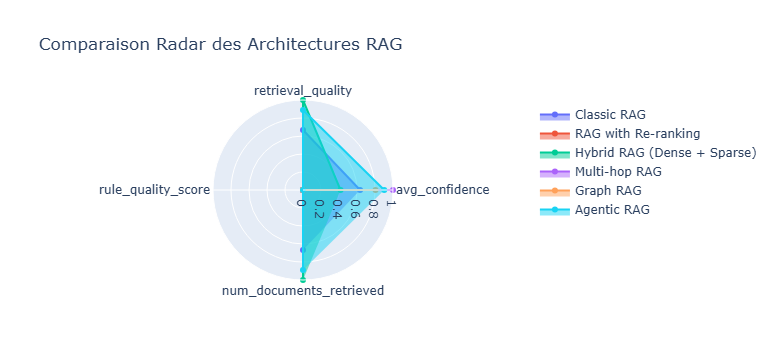

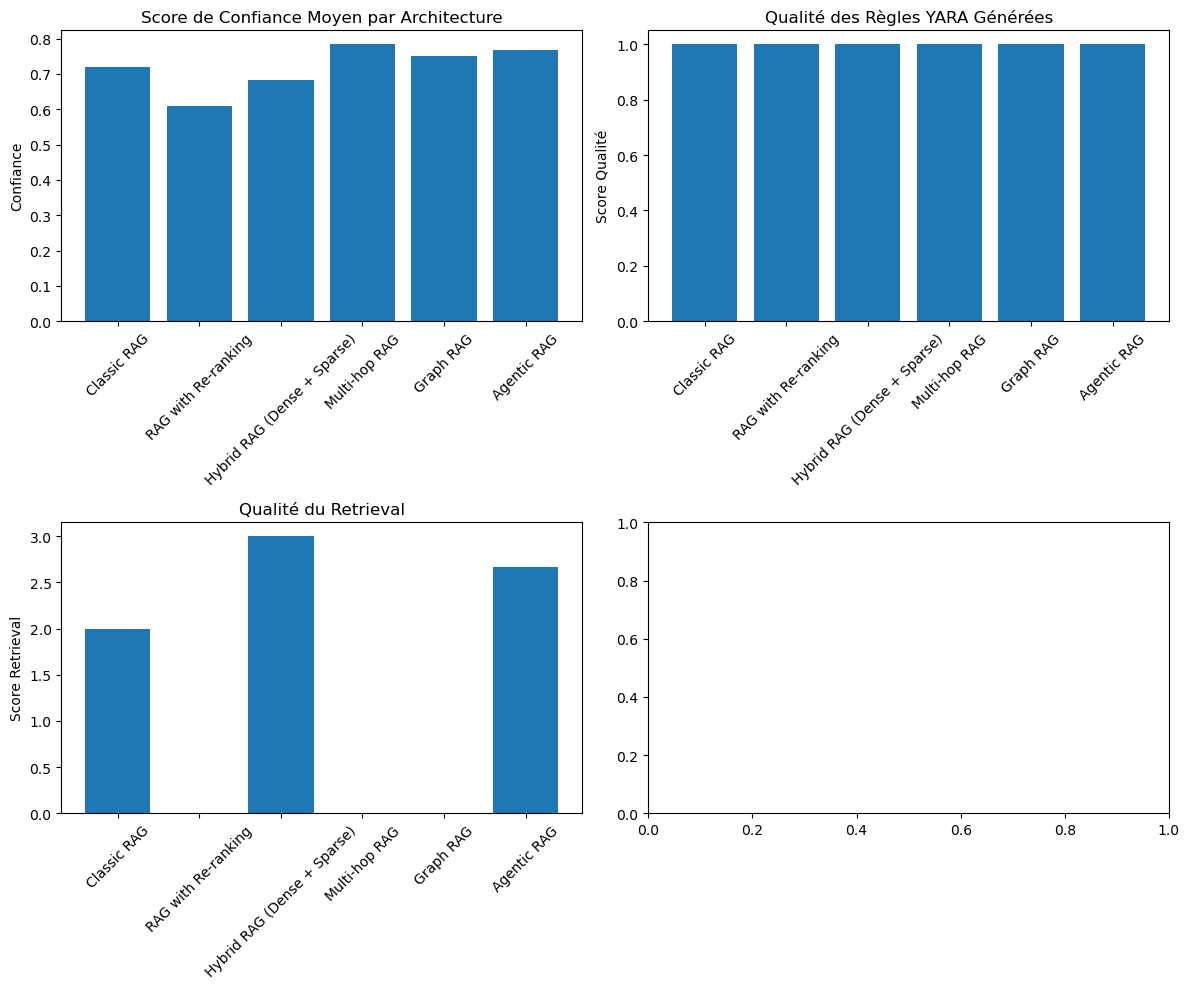